In [33]:
#@title библиотеки
!pip install mplcyberpunk

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import mplcyberpunk

plt.style.use("cyberpunk")

from google.colab import files
from copy import deepcopy
from itertools import combinations
from collections import Counter

In [34]:
#@title Общее число строк
dataset = pd.read_excel('form_dodreg2025_6a737ed576165.xlsx')

dataset.shape

(4881, 7)

In [35]:
# @title
#dataset = dataset.drop_duplicates(subset = ['Фамилия и Имя'])
dataset = dataset.dropna(subset=['Дата мероприятия'])
dataset[dataset['Дата мероприятия'].str.contains('22 ноября')].shape

(144, 7)

In [36]:
# @title
dataset['Дата мероприятия'] = dataset['Дата мероприятия'].astype(str).str.replace(', колледж', '; колледж' )
dataset[dataset['Дата мероприятия'].str.contains('22 ноября')].shape

(144, 7)

In [37]:
# @title
# dataset['Дата мероприятия'] = dataset['Дата мероприятия'].astype(str).str.split(',')
dataset[dataset['Дата мероприятия'].str.contains('22 ноября')].shape

(144, 7)

In [38]:
#@title
dataset_exploded = dataset
dataset_exploded['Дата мероприятия'] = dataset_exploded['Дата мероприятия'].str.split(', ')
print(dataset_exploded['Дата мероприятия'])
dataset_exploded = dataset_exploded.explode('Дата мероприятия').reset_index(drop=True)
output_file = 'form_dodreg_split_events.xlsx'
dataset_exploded.to_excel(output_file, index=False)
dataset_exploded.shape
print('===============================')
print(dataset_exploded['Дата мероприятия'])

0                                  [17 февраля 2024 года]
1                                  [17 февраля 2024 года]
2                                  [17 февраля 2024 года]
3       [17 февраля 2024 года, 28 февраля 2024 года (о...
4                         [28 февраля 2024 года (онлайн)]
                              ...                        
4876                                       [15 июля 2026]
4877                                       [15 июля 2026]
4878                                       [15 июля 2026]
4879                                       [15 июля 2026]
4880                                       [15 июля 2026]
Name: Дата мероприятия, Length: 4881, dtype: object
0                17 февраля 2024 года
1                17 февраля 2024 года
2                17 февраля 2024 года
3                17 февраля 2024 года
4       28 февраля 2024 года (онлайн)
                    ...              
5080                     15 июля 2026
5081                     15 июля 2026
5082  

In [39]:
# @title
#dataset_exploded['Дата мероприятия'] = dataset_exploded['Дата мероприятия'].str.strip()

In [40]:
# @title
# output_file = 'form_dodreg_split_events.xlsx'
# dataset_exploded.to_excel(output_file, index=False)

# dataset = pd.read_excel('form_dodreg_split_events.xlsx')

# dataset.shape

In [41]:
#@title *
spisok_utm = ['ysclid', 'yclid', 'postupi_online', 'erid', 'tag', 'dni-otkrytykh-dverey', 'yandex', 'vk_ads','vuzopedia','ucheba', '=YandexDirect', 'tg', 'shag_ad', 'source=newsletter','college', 'Yandex', 'Yandex_dod_22', 'shag_nov']
DATE = '28 февраля 2024 года (онлайн)'



def data_dod(big_table, date_event): #data_dod -функция на выгрузку даты по строкам мероприятия
  # return  big_table.loc[big_table['Дата мероприятия'].str.contains(date_event)][['Дата мероприятия', 'URL отправки']]
  return  big_table[big_table['Дата мероприятия'].apply(lambda x: date_event in x)][['Дата мероприятия', 'URL отправки']]

#sylka1 = data_dod(dataset, DATE)


def utm(name_utm, sylka):
  return sylka[sylka['URL отправки'].str.contains(name_utm)].shape[0]

def result_utm(utms, sylka):
  tmp = []
  for i in utms:
    tmp.append(utm(i, sylka))

  return tmp

def total_print(big_table, date_event, utms):
  return result_utm(utms, data_dod(big_table, date_event))

finals_utms = total_print(dataset, DATE, spisok_utm)

print(finals_utms)
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

[1, 0, 2, 17, 2, 19, 12, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
ysclid 1
yclid 0
postupi_online 2
erid 17
tag 2
dni-otkrytykh-dverey 19
yandex 12
vk_ads 1
vuzopedia 0
ucheba 0
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 0
college 0
Yandex 0
Yandex_dod_22 0
shag_nov 0


[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

In [42]:
#@title .

def grafic(x,y):

  fig, ax = plt.subplots()
  colors = [(np.random.random(), np.random.random(), np.random.random()) for i in range(len(x))]
  #ax.bar(x,y, zorder = 2)
  ax.set_xticks([])
  #def set_bar(x,y, color, label):
  #    ax.bar(x,y, color=color, label=label)
  #for i in range (len(x)):
  #    color = (np.random.random(), np.random.random(), np.random.random())
  #    set_bar(x[i], y[i], color=color, label= x[i])

  bars = ax.bar(x, y, color=colors, label=x, width=0.9)
  plt.xticks(rotation=6, positions = [i * 3 for i in range(len(x))])
  plt.legend(bbox_to_anchor=(1.5, 1))
  ax.set_ylabel('Метки')
  ax.set_xlabel('UTM')
  mplcyberpunk.add_bar_gradient(bars=bars)
  plt.show()

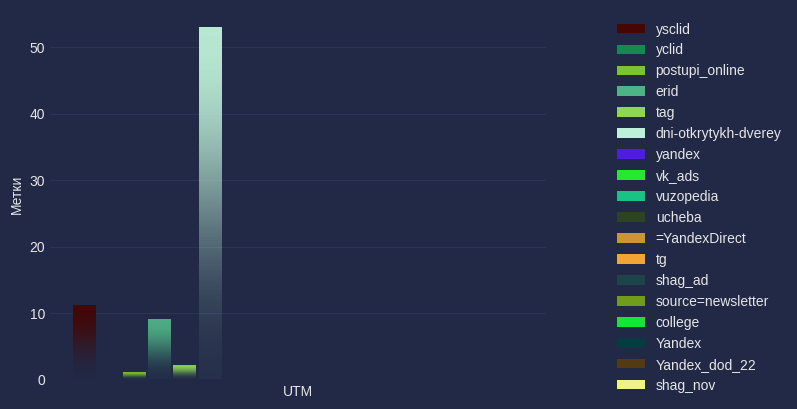

[11, 0, 1, 9, 2, 53, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [43]:
#@title Визуализация UTM на ДОД 17 февраля 2024 года
finals_utms = total_print(dataset, '17 февраля 2024 года', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [44]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '17 февраля 2024 года')
sylka1.shape

ysclid 11
yclid 0
postupi_online 1
erid 9
tag 2
dni-otkrytykh-dverey 53
yandex 0
vk_ads 0
vuzopedia 0
ucheba 0
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 0
college 0
Yandex 0
Yandex_dod_22 0
shag_nov 0


(153, 2)

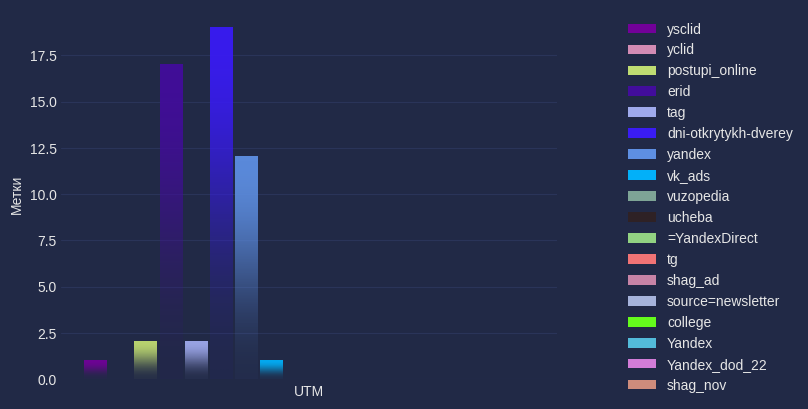

[1, 0, 2, 17, 2, 19, 12, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [45]:
#@title Визуализация UTM на ДОД 28 февраля 2024 года (онлайн)
finals_utms = total_print(dataset, '28 февраля 2024 года (онлайн)', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)


In [46]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '28 февраля 2024 года (онлайн)')
sylka1.shape

ysclid 1
yclid 0
postupi_online 2
erid 17
tag 2
dni-otkrytykh-dverey 19
yandex 12
vk_ads 1
vuzopedia 0
ucheba 0
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 0
college 0
Yandex 0
Yandex_dod_22 0
shag_nov 0


(77, 2)

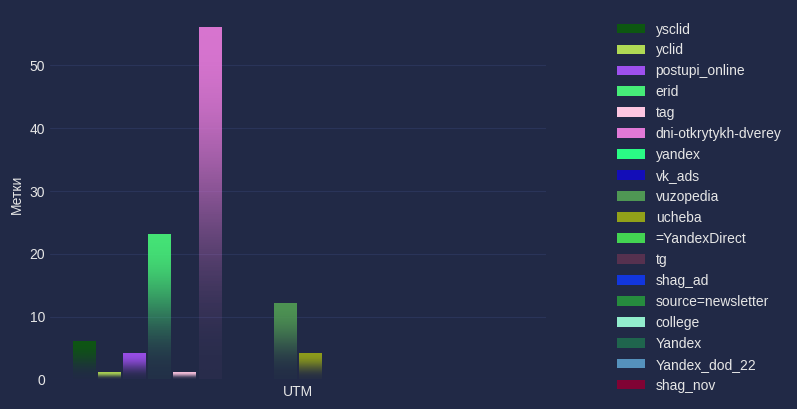

[6, 1, 4, 23, 1, 56, 0, 0, 12, 4, 0, 0, 0, 0, 0, 0, 0, 0]


In [47]:
#@title Визуализация UTM на ДОД 16 марта 2024 года
finals_utms = total_print(dataset, '16 марта 2024 года', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [48]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]
sylka1 = data_dod(dataset, '16 марта 2024 года')
sylka1.shape

ysclid 6
yclid 1
postupi_online 4
erid 23
tag 1
dni-otkrytykh-dverey 56
yandex 0
vk_ads 0
vuzopedia 12
ucheba 4
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 0
college 0
Yandex 0
Yandex_dod_22 0
shag_nov 0


(150, 2)

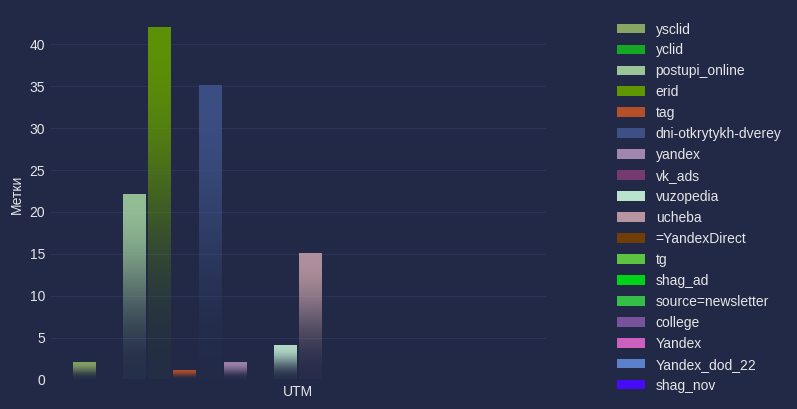

[2, 0, 22, 42, 1, 35, 2, 0, 4, 15, 0, 0, 0, 0, 0, 0, 0, 0]


In [49]:
#@title Визуализация UTM на ДОД 30 марта 2024 года (онлайн)

finals_utms = total_print(dataset, '30 марта 2024 года (онлайн)', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [50]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '30 марта 2024 года (онлайн)')
sylka1.shape

ysclid 2
yclid 0
postupi_online 22
erid 42
tag 1
dni-otkrytykh-dverey 35
yandex 2
vk_ads 0
vuzopedia 4
ucheba 15
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 0
college 0
Yandex 0
Yandex_dod_22 0
shag_nov 0


(129, 2)

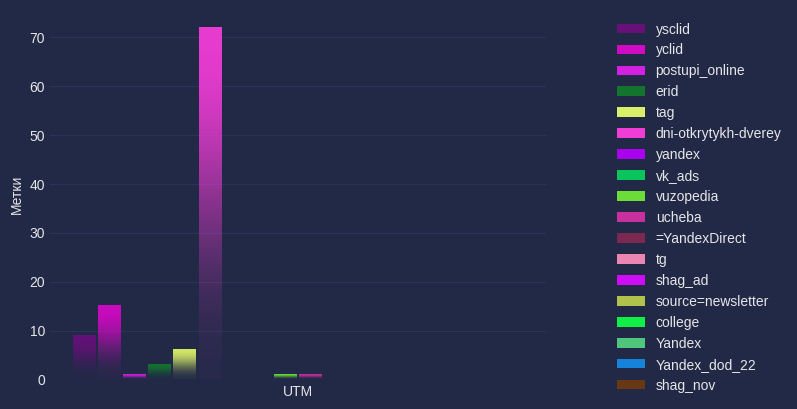

[9, 15, 1, 3, 6, 72, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0]


In [51]:
#@title Визуализация UTM на ДОД 13 апреля 2024 года

finals_utms = total_print(dataset, '13 апреля 2024 года', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [52]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '13 апреля 2024 года')
sylka1.shape

ysclid 9
yclid 15
postupi_online 1
erid 3
tag 6
dni-otkrytykh-dverey 72
yandex 0
vk_ads 0
vuzopedia 1
ucheba 1
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 0
college 0
Yandex 0
Yandex_dod_22 0
shag_nov 0


(171, 2)

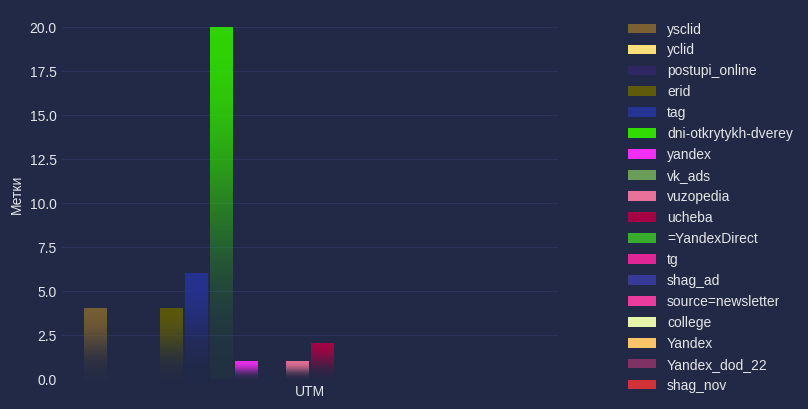

[4, 0, 0, 4, 6, 20, 1, 0, 1, 2, 0, 0, 0, 0, 0, 0, 0, 0]


In [53]:
#@title Визуализация UTM на ДОД 18 мая 2024 года (онлайн)

finals_utms = total_print(dataset, '18 мая 2024 года (онлайн)', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [54]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '18 мая 2024 года (онлайн)')
sylka1.shape

ysclid 4
yclid 0
postupi_online 0
erid 4
tag 6
dni-otkrytykh-dverey 20
yandex 1
vk_ads 0
vuzopedia 1
ucheba 2
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 0
college 0
Yandex 0
Yandex_dod_22 0
shag_nov 0


(95, 2)

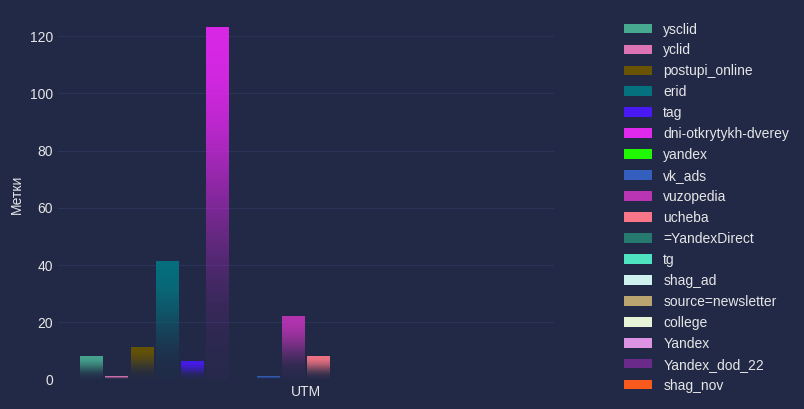

[8, 1, 11, 41, 6, 123, 0, 1, 22, 8, 0, 0, 0, 0, 0, 0, 0, 0]


In [55]:
#@title Визуализация UTM на ДОД 29 июня 2024 года

finals_utms = total_print(dataset, '29 июня 2024 года', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [56]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '29 июня 2024 года')
sylka1.shape

ysclid 8
yclid 1
postupi_online 11
erid 41
tag 6
dni-otkrytykh-dverey 123
yandex 0
vk_ads 1
vuzopedia 22
ucheba 8
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 0
college 0
Yandex 0
Yandex_dod_22 0
shag_nov 0


(411, 2)

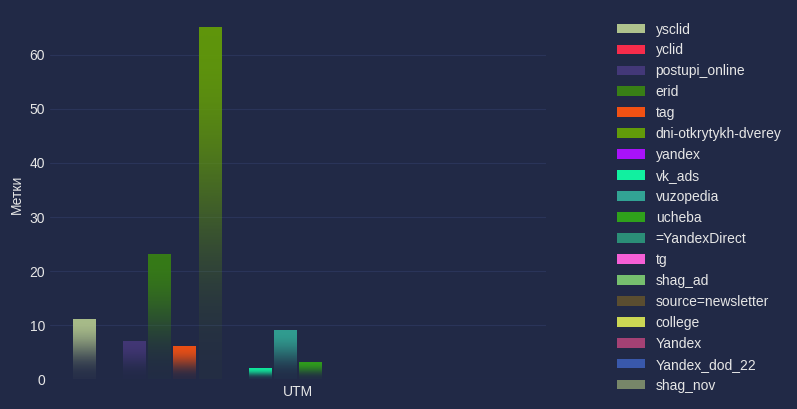

[11, 0, 7, 23, 6, 65, 0, 2, 9, 3, 0, 0, 0, 0, 0, 0, 0, 0]


In [57]:
#@title  Визуализация UTM на ДОД 13 июля 2024 года

finals_utms = total_print(dataset, '13 июля 2024 года', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [58]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '13 июля 2024 года')
sylka1.shape

ysclid 11
yclid 0
postupi_online 7
erid 23
tag 6
dni-otkrytykh-dverey 65
yandex 0
vk_ads 2
vuzopedia 9
ucheba 3
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 0
college 0
Yandex 0
Yandex_dod_22 0
shag_nov 0


(208, 2)

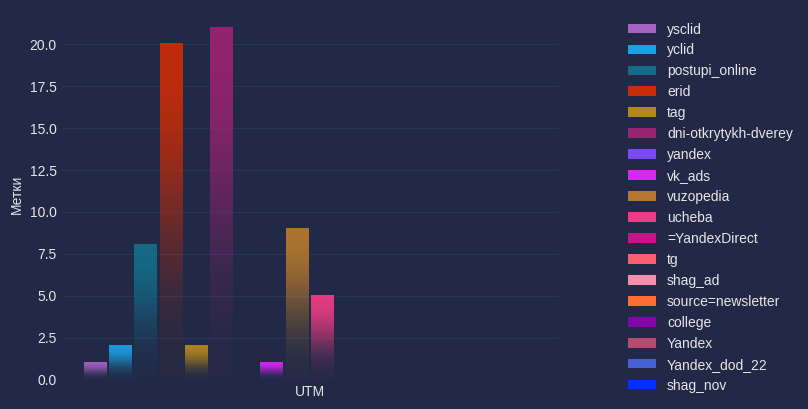

[1, 2, 8, 20, 2, 21, 0, 1, 9, 5, 0, 0, 0, 0, 0, 0, 0, 0]


In [59]:
#@title  Визуализация UTM на ДОД 12 октября 2024 года

finals_utms = total_print(dataset, '12 октября', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [60]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '12 октября')
sylka1.shape

ysclid 1
yclid 2
postupi_online 8
erid 20
tag 2
dni-otkrytykh-dverey 21
yandex 0
vk_ads 1
vuzopedia 9
ucheba 5
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 0
college 0
Yandex 0
Yandex_dod_22 0
shag_nov 0


(88, 2)

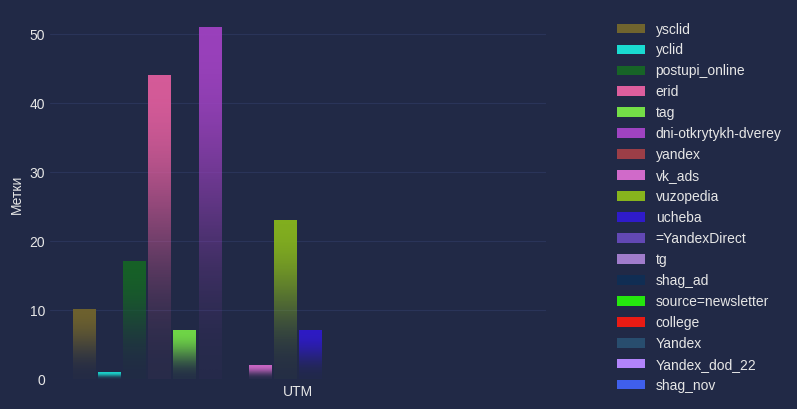

[10, 1, 17, 44, 7, 51, 0, 2, 23, 7, 0, 0, 0, 0, 0, 0, 0, 0]


In [61]:
#@title  Визуализация UTM на ДОД 16 ноября 2024 года 2024 года

finals_utms = total_print(dataset, '16 ноября', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [62]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '16 ноября')
sylka1.shape

ysclid 10
yclid 1
postupi_online 17
erid 44
tag 7
dni-otkrytykh-dverey 51
yandex 0
vk_ads 2
vuzopedia 23
ucheba 7
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 0
college 0
Yandex 0
Yandex_dod_22 0
shag_nov 0


(157, 2)

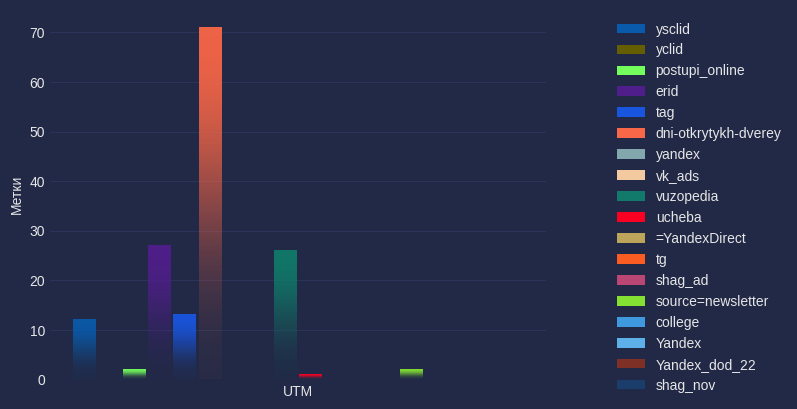

[12, 0, 2, 27, 13, 71, 0, 0, 26, 1, 0, 0, 0, 2, 0, 0, 0, 0]


In [63]:
#@title  Визуализация UTM на ДОД 8 февраля 2025

finals_utms = total_print(dataset, '8 февраля 2025', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [64]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '8 февраля 2025')
sylka1.shape

ysclid 12
yclid 0
postupi_online 2
erid 27
tag 13
dni-otkrytykh-dverey 71
yandex 0
vk_ads 0
vuzopedia 26
ucheba 1
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 2
college 0
Yandex 0
Yandex_dod_22 0
shag_nov 0


(185, 2)

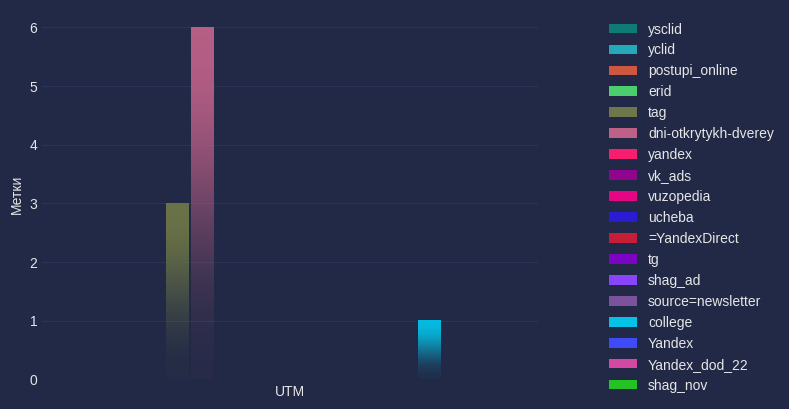

[0, 0, 0, 0, 3, 6, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0]


In [65]:
#@title Визуализация UTM на ДОД 5 марта 2025

finals_utms = total_print(dataset, '5 марта 2025', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [66]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]
sylka1 = data_dod(dataset, '5 марта 2025')
sylka1.shape

ysclid 0
yclid 0
postupi_online 0
erid 0
tag 3
dni-otkrytykh-dverey 6
yandex 0
vk_ads 0
vuzopedia 0
ucheba 0
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 0
college 1
Yandex 0
Yandex_dod_22 0
shag_nov 0


(35, 2)

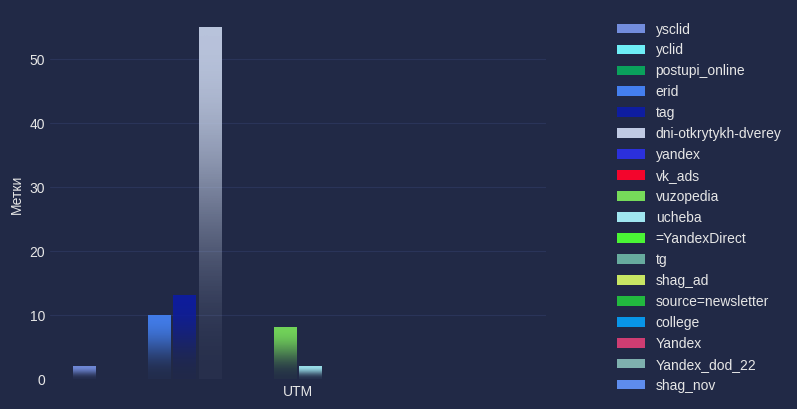

[2, 0, 0, 10, 13, 55, 0, 0, 8, 2, 0, 0, 0, 0, 0, 0, 0, 0]


In [67]:
#@title Визуализация UTM на ДОД 22 марта 2025

finals_utms = total_print(dataset, '22 марта 2025', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [68]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '22 марта 2025')
sylka1.shape

ysclid 2
yclid 0
postupi_online 0
erid 10
tag 13
dni-otkrytykh-dverey 55
yandex 0
vk_ads 0
vuzopedia 8
ucheba 2
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 0
college 0
Yandex 0
Yandex_dod_22 0
shag_nov 0


(155, 2)

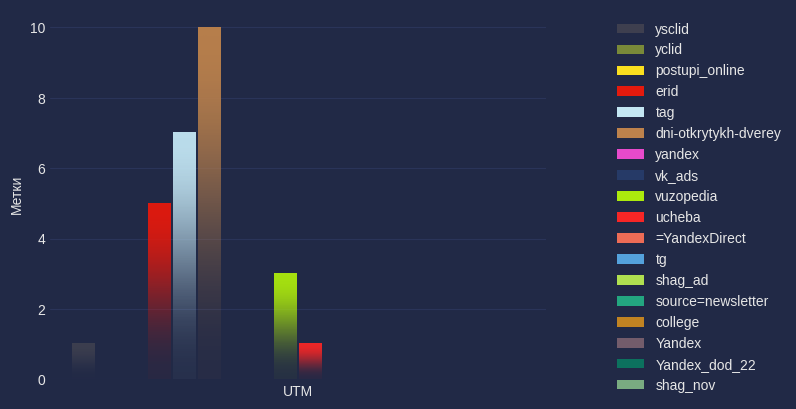

[1, 0, 0, 5, 7, 10, 0, 0, 3, 1, 0, 0, 0, 0, 0, 0, 0, 0]


In [69]:
#@title Визуализация UTM на ДОД 19 апреля 2025

finals_utms = total_print(dataset, '19 апреля 2025', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [70]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '19 апреля 2025')
sylka1.shape

ysclid 1
yclid 0
postupi_online 0
erid 5
tag 7
dni-otkrytykh-dverey 10
yandex 0
vk_ads 0
vuzopedia 3
ucheba 1
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 0
college 0
Yandex 0
Yandex_dod_22 0
shag_nov 0


(43, 2)

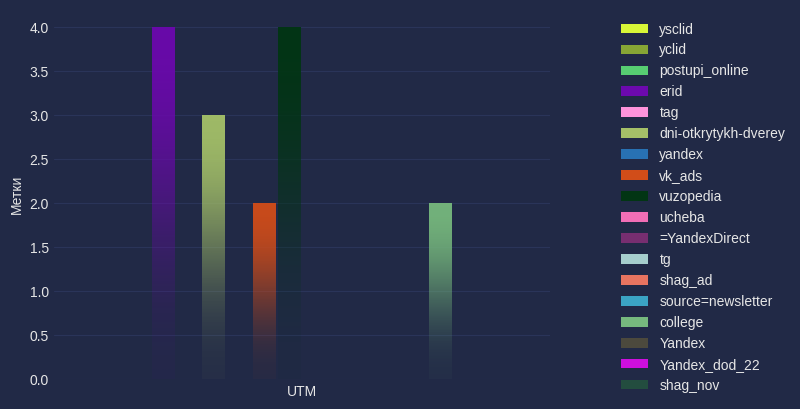

[0, 0, 0, 4, 0, 3, 0, 2, 4, 0, 0, 0, 0, 0, 2, 0, 0, 0]


In [71]:
#@title Визуализация UTM на ДОД 23 апреля 2025 (онлайн)

finals_utms = total_print(dataset, '23 апреля 2025 (онлайн)', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [72]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '23 апреля 2025 (онлайн)')
sylka1.shape

ysclid 0
yclid 0
postupi_online 0
erid 4
tag 0
dni-otkrytykh-dverey 3
yandex 0
vk_ads 2
vuzopedia 4
ucheba 0
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 0
college 2
Yandex 0
Yandex_dod_22 0
shag_nov 0


(26, 2)

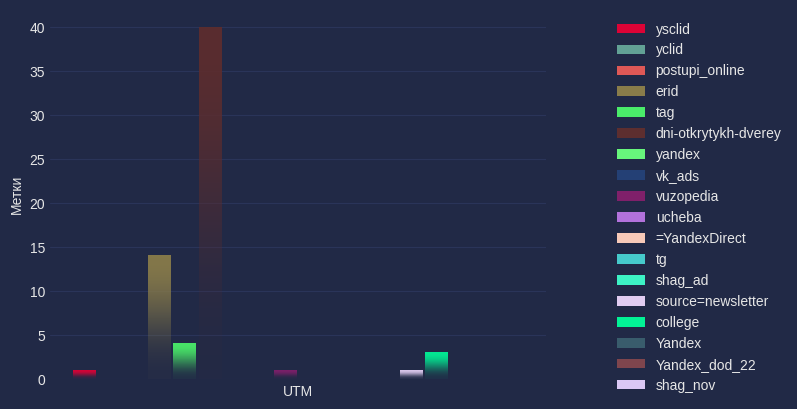

[1, 0, 0, 14, 4, 40, 0, 0, 1, 0, 0, 0, 0, 1, 3, 0, 0, 0]


In [73]:
#@title Визуализация UTM на ДОД 17 мая 2025

finals_utms = total_print(dataset, '17 мая 2025', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [74]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '17 мая 2025')
sylka1.shape

ysclid 1
yclid 0
postupi_online 0
erid 14
tag 4
dni-otkrytykh-dverey 40
yandex 0
vk_ads 0
vuzopedia 1
ucheba 0
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 1
college 3
Yandex 0
Yandex_dod_22 0
shag_nov 0


(120, 2)

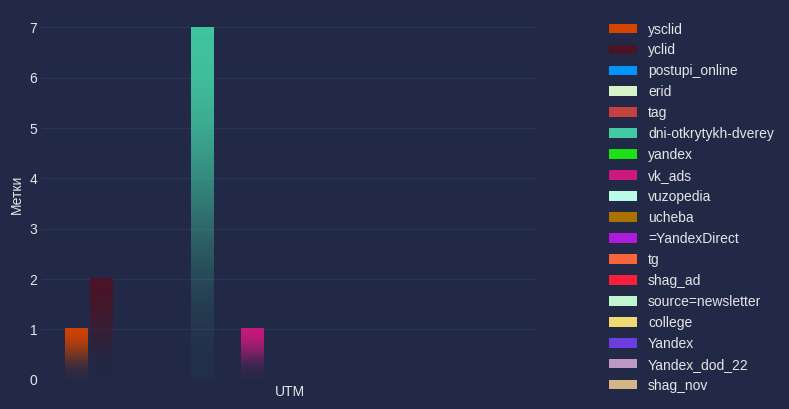

[1, 2, 0, 0, 0, 7, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [75]:
#@title Визуализация UTM на ДОД 6 июня 2025 (онлайн)

finals_utms = total_print(dataset, '6 июня 2025 (онлайн)', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [76]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '6 июня 2025 (онлайн)')
sylka1.shape

ysclid 1
yclid 2
postupi_online 0
erid 0
tag 0
dni-otkrytykh-dverey 7
yandex 0
vk_ads 1
vuzopedia 0
ucheba 0
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 0
college 0
Yandex 0
Yandex_dod_22 0
shag_nov 0


(39, 2)

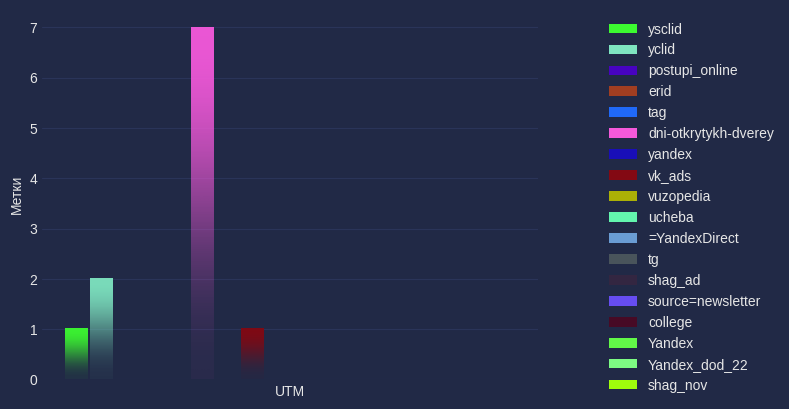

[1, 2, 0, 0, 0, 7, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [77]:
#@title Визуализация UTM на ДОД 21 июня 2025 года (онлайн)

finals_utms = total_print(dataset, '6 июня 2025 (онлайн)', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [78]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '6 июня 2025 (онлайн)')
sylka1.shape

ysclid 1
yclid 2
postupi_online 0
erid 0
tag 0
dni-otkrytykh-dverey 7
yandex 0
vk_ads 1
vuzopedia 0
ucheba 0
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 0
college 0
Yandex 0
Yandex_dod_22 0
shag_nov 0


(39, 2)

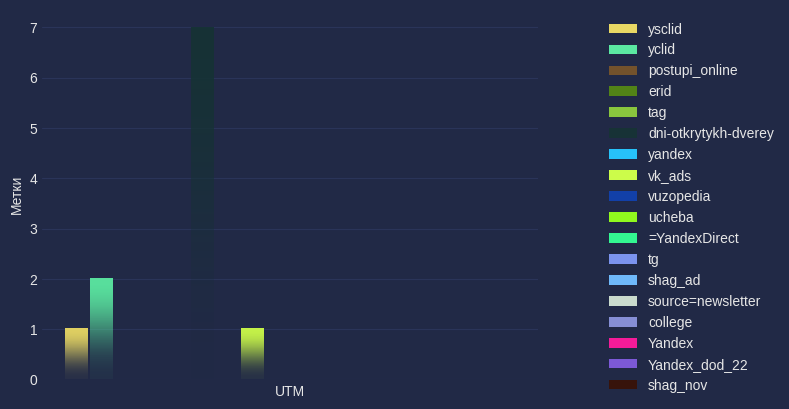

[1, 2, 0, 0, 0, 7, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [79]:
#@title Визуализация UTM на ДОД 6 июня 2025 года (онлайн)

finals_utms = total_print(dataset, '6 июня 2025 (онлайн)', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [80]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '6 июня 2025 (онлайн)')
sylka1.shape

ysclid 1
yclid 2
postupi_online 0
erid 0
tag 0
dni-otkrytykh-dverey 7
yandex 0
vk_ads 1
vuzopedia 0
ucheba 0
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 0
college 0
Yandex 0
Yandex_dod_22 0
shag_nov 0


(39, 2)

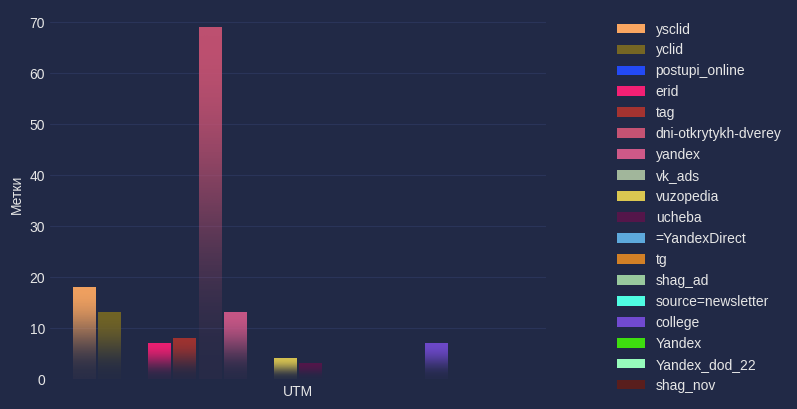

[18, 13, 0, 7, 8, 69, 13, 0, 4, 3, 0, 0, 0, 0, 7, 0, 0, 0]


In [81]:
#@title Визуализация UTM на ДОД 5 июля 2025 года (очно)

finals_utms = total_print(dataset, '5 июля 2025 (очно)', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [82]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '5 июля 2025 (очно)')
sylka1.shape

ysclid 18
yclid 13
postupi_online 0
erid 7
tag 8
dni-otkrytykh-dverey 69
yandex 13
vk_ads 0
vuzopedia 4
ucheba 3
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 0
college 7
Yandex 0
Yandex_dod_22 0
shag_nov 0


(297, 2)

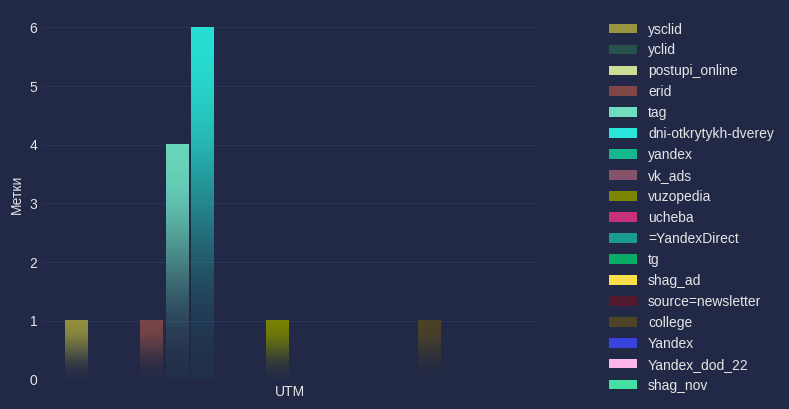

[1, 0, 0, 1, 4, 6, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0]


In [83]:
 #@title Визуализация UTM на ДОД 24 июня 2025 года (онлайн, колледж)

finals_utms = total_print(dataset, '24 июня 2025 (онлайн; колледж)', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [84]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '24 июня 2025 (онлайн; колледж)')
sylka1.shape



ysclid 1
yclid 0
postupi_online 0
erid 1
tag 4
dni-otkrytykh-dverey 6
yandex 0
vk_ads 0
vuzopedia 1
ucheba 0
=YandexDirect 0
tg 0
shag_ad 0
source=newsletter 0
college 1
Yandex 0
Yandex_dod_22 0
shag_nov 0


(50, 2)

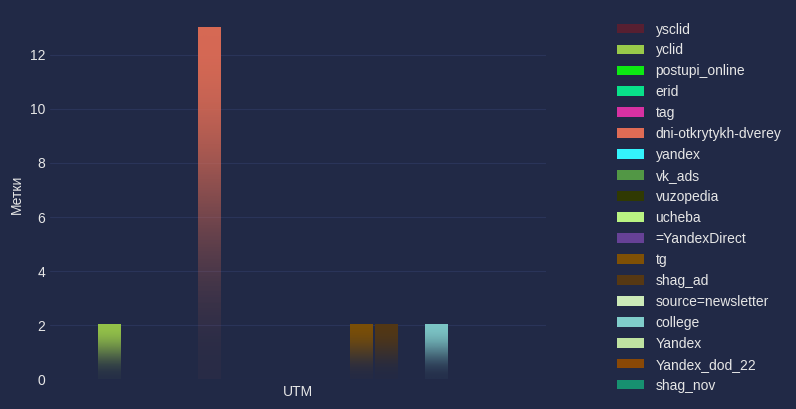

[0, 2, 0, 0, 0, 13, 0, 0, 0, 0, 0, 2, 2, 0, 2, 0, 0, 0]


In [85]:
 #@title Визуализация UTM на ДОД 12 августа 2025 года

finals_utms = total_print(dataset, '12 августа 2025 (очно)', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [86]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '12 августа 2025 (очно)')
sylka1.shape

ysclid 0
yclid 2
postupi_online 0
erid 0
tag 0
dni-otkrytykh-dverey 13
yandex 0
vk_ads 0
vuzopedia 0
ucheba 0
=YandexDirect 0
tg 2
shag_ad 2
source=newsletter 0
college 2
Yandex 0
Yandex_dod_22 0
shag_nov 0


(69, 2)

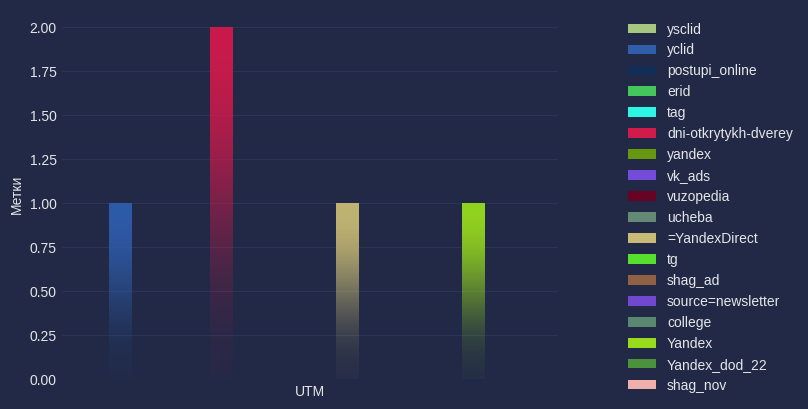

[0, 1, 0, 0, 0, 2, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0]


In [87]:
 #@title Визуализация UTM на ДОД 14 августа 2025 (онлайн)

finals_utms = total_print(dataset, '14 августа 2025 (дистанционно)', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [88]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '14 августа 2025 (дистанционно)')
sylka1.shape

ysclid 0
yclid 1
postupi_online 0
erid 0
tag 0
dni-otkrytykh-dverey 2
yandex 0
vk_ads 0
vuzopedia 0
ucheba 0
=YandexDirect 1
tg 0
shag_ad 0
source=newsletter 0
college 0
Yandex 1
Yandex_dod_22 0
shag_nov 0


(29, 2)

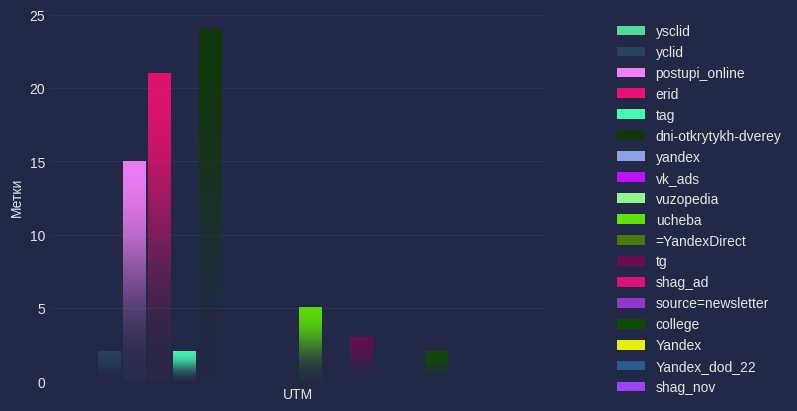

[0, 2, 15, 21, 2, 24, 0, 0, 0, 5, 0, 3, 0, 0, 2, 0, 0, 0]


In [89]:
 #@title Визуализация UTM на ДОД 25 октября 2025

finals_utms = total_print(dataset, '25 октября 2025', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [90]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '25 октября 2025')
sylka1.shape

ysclid 0
yclid 2
postupi_online 15
erid 21
tag 2
dni-otkrytykh-dverey 24
yandex 0
vk_ads 0
vuzopedia 0
ucheba 5
=YandexDirect 0
tg 3
shag_ad 0
source=newsletter 0
college 2
Yandex 0
Yandex_dod_22 0
shag_nov 0


(84, 2)

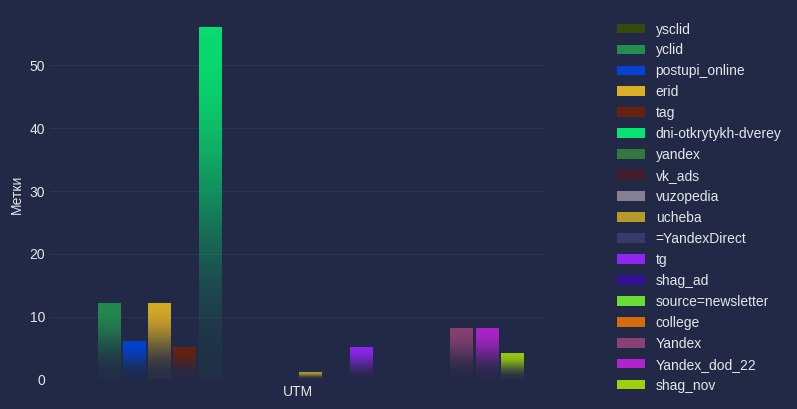

[0, 12, 6, 12, 5, 56, 0, 0, 0, 1, 0, 5, 0, 0, 0, 8, 8, 4]


In [91]:
 #@title Визуализация UTM на ДОД 22 ноября 2025

finals_utms = total_print(dataset, '22 ноября 2025', spisok_utm)
grafic(spisok_utm, finals_utms)

print(finals_utms)

In [92]:
# @title
[print(spisok_utm[i], finals_utms[i]) for i in range(len(spisok_utm))]

sylka1 = data_dod(dataset, '22 ноября 2025')

sylka1.shape

ysclid 0
yclid 12
postupi_online 6
erid 12
tag 5
dni-otkrytykh-dverey 56
yandex 0
vk_ads 0
vuzopedia 0
ucheba 1
=YandexDirect 0
tg 5
shag_ad 0
source=newsletter 0
college 0
Yandex 8
Yandex_dod_22 8
shag_nov 4


(144, 2)

ysclid 12
yclid 23
postupi_online 2
erid 11
tag 2
dni-otkrytykh-dverey 34
dod-07-02-2026 185
yandex 22
vk_ads 0
YandexDirect 1
tg_shag_feb 1
moy_obraz_feb_dod 1
priemnaya_komissiya_rosnou 7
college 3
Yandex 1
yandex_pg_feb 22


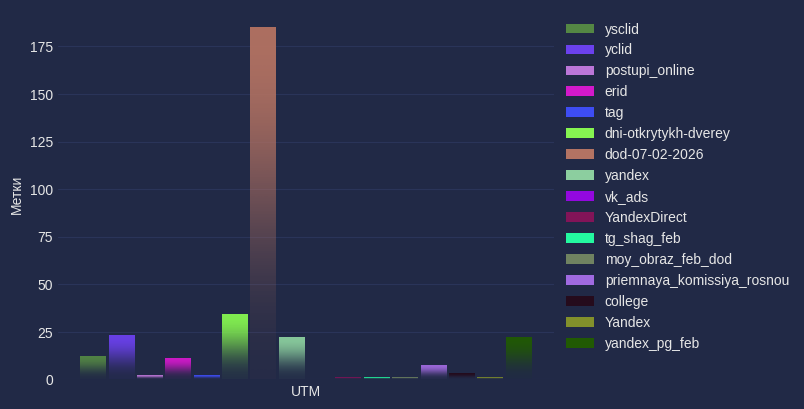

[12, 23, 2, 11, 2, 34, 185, 22, 0, 1, 1, 1, 7, 3, 1, 22]


(242, 2)

In [93]:
# @title Визуализация UTM на ДОД 7 февраля 2026
spisok_utm1 = ['ysclid', 'yclid', 'postupi_online', 'erid', 'tag', 'dni-otkrytykh-dverey', 'dod-07-02-2026', 'yandex', 'vk_ads', 'YandexDirect', 'tg_shag_feb', 'moy_obraz_feb_dod', 'priemnaya_komissiya_rosnou','college', 'Yandex', 'yandex_pg_feb']
finals_utms = total_print(dataset, '7 февраля 2026', spisok_utm1)

[print(spisok_utm1[i], finals_utms[i]) for i in range(len(spisok_utm1))]

sylka1 = data_dod(dataset, '7 февраля 2026')

grafic(spisok_utm1, finals_utms)

print(finals_utms)

sylka1.shape

ysclid 2
yclid 2
postupi_online 0
erid 1
tag 0
dni-otkrytykh-dverey 0
dod-21-02-2026 2
yandex 1
vk_ads 2
YandexDirect 0
priemnaya_komissiya_rosnou 0
college 0
Yandex 0


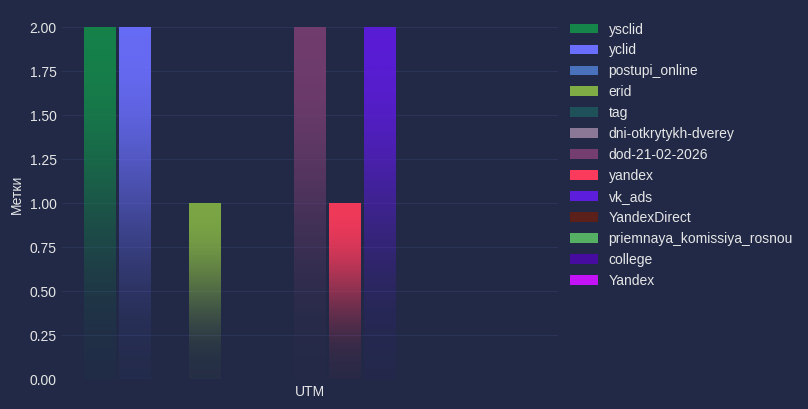

[2, 2, 0, 1, 0, 0, 2, 1, 2, 0, 0, 0, 0]


(61, 2)

In [94]:
# @title UTM на ДОД 28 марта (онлайн)
spisok_utm1 = ['ysclid', 'yclid', 'postupi_online', 'erid', 'tag', 'dni-otkrytykh-dverey', 'dod-21-02-2026', 'yandex', 'vk_ads', 'YandexDirect', 'priemnaya_komissiya_rosnou','college', 'Yandex', ]
finals_utms = total_print(dataset, '28 марта (онлайн)', spisok_utm1)

[print(spisok_utm1[i], finals_utms[i]) for i in range(len(spisok_utm1))]

sylka1 = data_dod(dataset, '28 марта (онлайн)')

grafic(spisok_utm1, finals_utms)

print(finals_utms)

sylka1.shape

ysclid 4
yclid 6
postupi_online 2
erid 6
tag 0
dni-otkrytykh-dverey 1
dod-14-03-2026 149
yandex 5
vk_ads 3
vuzopedia 0
ucheba 1
=YandexDirect 1
tg 0
source=newsletter 2
college 0
Yandex 1
yandex_pg_feb 2
yandex_pg 5


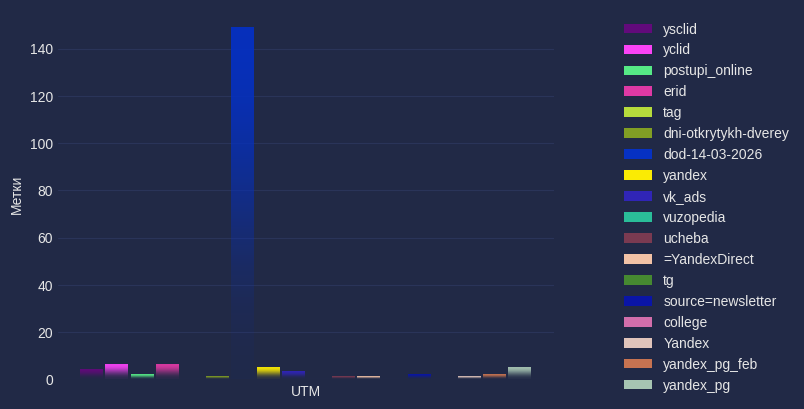

[4, 6, 2, 6, 0, 1, 149, 5, 3, 0, 1, 1, 0, 2, 0, 1, 2, 5]


(188, 2)

In [95]:
# @title UTM на ДОД 14 марта 2026
spisok_utm1 = ['ysclid', 'yclid', 'postupi_online', 'erid', 'tag', 'dni-otkrytykh-dverey', 'dod-14-03-2026', 'yandex', 'vk_ads','vuzopedia','ucheba', '=YandexDirect', 'tg', 'source=newsletter','college', 'Yandex', 'yandex_pg_feb', 'yandex_pg' ]
finals_utms = total_print(dataset, '14 марта 2026', spisok_utm1)

[print(spisok_utm1[i], finals_utms[i]) for i in range(len(spisok_utm1))]

sylka1 = data_dod(dataset, '14 марта 2026')

grafic(spisok_utm1, finals_utms)

print(finals_utms)

sylka1.shape

ysclid 2
yclid 35
postupi_online 1
erid 17
tag 0
dni-otkrytykh-dverey 1
dod-07-02-2026 2
dod-14-03-2026 6
dod-11-04-2026 159
yandex 12
vk_ads 1
vkontakte 1
=YandexDirect 1
tg 0
source=newsletter 0
college 0
Yandex 1
banner_ucheba_11_april 13
ucheba_mail_dod_11aprl 3
yandex_rsya_11_april 12
ege_pg_april 25
pg_april 27


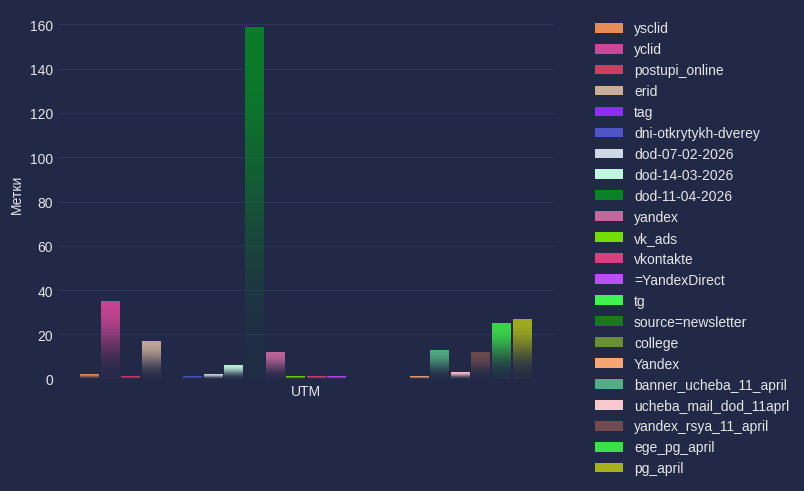

[2, 35, 1, 17, 0, 1, 2, 6, 159, 12, 1, 1, 1, 0, 0, 0, 1, 13, 3, 12, 25, 27]


(186, 2)

In [96]:
# @title UTM на ДОД 11 апреля 2026
spisok_utm1 = ['ysclid', 'yclid', 'postupi_online', 'erid', 'tag', 'dni-otkrytykh-dverey', 'dod-07-02-2026', 'dod-14-03-2026', 'dod-11-04-2026', 'yandex', 'vk_ads','vkontakte', '=YandexDirect', 'tg','source=newsletter','college', 'Yandex','banner_ucheba_11_april', 'ucheba_mail_dod_11aprl', 'yandex_rsya_11_april', 'ege_pg_april', 'pg_april' ]
finals_utms = total_print(dataset, '11 апреля 2026', spisok_utm1)

[print(spisok_utm1[i], finals_utms[i]) for i in range(len(spisok_utm1))]

sylka1 = data_dod(dataset, '11 апреля 2026')

grafic(spisok_utm1, finals_utms)

print(finals_utms)

sylka1.shape

ysclid 0
yclid 0
postupi_online 0
erid 4
tag 0
dni-otkrytykh-dverey 0
yandex 0
vk_ads 2
ucheba_mail_dod_11aprl 3
=YandexDirect 0
source=newsletter 0
college 0
Yandex 0
dod-21-02-2026 1
dod-28-03-2026 2
dod-11-04-2026 7
dod-25-04-2026 37
dod-16-05-2026 4


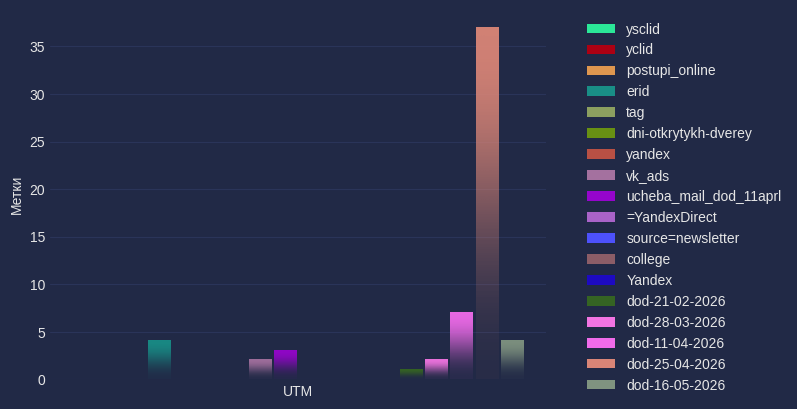

[0, 0, 0, 4, 0, 0, 0, 2, 3, 0, 0, 0, 0, 1, 2, 7, 37, 4]


(52, 2)

In [97]:
# @title UTM на 25 апреля (онлайн)

spisok_utm1 = ['ysclid', 'yclid', 'postupi_online', 'erid', 'tag', 'dni-otkrytykh-dverey', 'yandex', 'vk_ads','ucheba_mail_dod_11aprl', '=YandexDirect',  'source=newsletter','college', 'Yandex', 'dod-21-02-2026', 'dod-28-03-2026', 'dod-11-04-2026', 'dod-25-04-2026', 'dod-16-05-2026']

finals_utms = total_print(dataset, '25 апреля (онлайн)', spisok_utm1)

[print(spisok_utm1[i], finals_utms[i]) for i in range(len(spisok_utm1))]

sylka1 = data_dod(dataset, '25 апреля (онлайн)')

grafic(spisok_utm1, finals_utms)

print(finals_utms)

sylka1.shape

ysclid 7
yclid 19
ege_pg_april 1
ege_may 2
rsya_may_dod 6
prk_bakalavr_may 1
ucheba_mail 3
kolledzh_may 6
ucheba_dod_may 10
postupi_anons_may 1
erid 15
tag 0
dni-otkrytykh-dverey 1
yandex 1
vk_ads 7
ucheba_mail_dod_11aprl 0
=YandexDirect 1
source=newsletter 1
college 0
Yandex 1
vitrina_maps_yandex 1
dod-11-04-2026 7
dod-25-04-2026 4
dod-16-05-2026 193


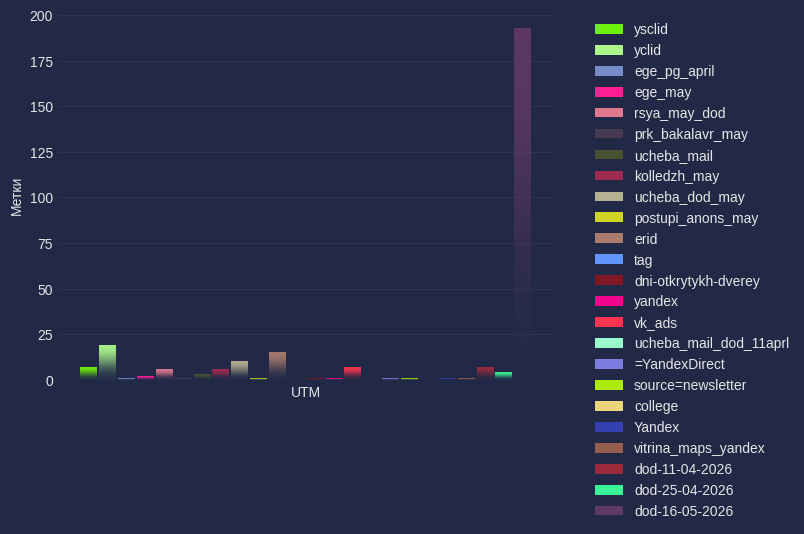

[7, 19, 1, 2, 6, 1, 3, 6, 10, 1, 15, 0, 1, 1, 7, 0, 1, 1, 0, 1, 1, 7, 4, 193]


(230, 2)

In [98]:
# @title UTM на 16 мая 2026

spisok_utm1 = ['ysclid', 'yclid', 'ege_pg_april','ege_may', 'rsya_may_dod', 'prk_bakalavr_may', 'ucheba_mail', 'kolledzh_may', 'ucheba_dod_may', 'postupi_anons_may', 'erid', 'tag', 'dni-otkrytykh-dverey', 'yandex', 'vk_ads','ucheba_mail_dod_11aprl', '=YandexDirect',  'source=newsletter','college', 'Yandex', 'vitrina_maps_yandex', 'dod-11-04-2026', 'dod-25-04-2026', 'dod-16-05-2026']

finals_utms = total_print(dataset, '16 мая 2026', spisok_utm1)

[print(spisok_utm1[i], finals_utms[i]) for i in range(len(spisok_utm1))]

sylka1 = data_dod(dataset, '16 мая 2026')

grafic(spisok_utm1, finals_utms)

print(finals_utms)

sylka1.shape

ysclid 1
yclid 1
erid 4
provuz 1
tag 0
rsya_may_dod 1
ucheba_dod_may 2
ucheba_mail 1
dni-otkrytykh-dverey 0
yandex 0
vk_ads 0
=YandexDirect 0
source=newsletter 0
college 0
Yandex 0
vitrina_maps_yandex 0
dod-21-02-2026 1
dod-11-04-2026 2
dod-25-04-2026 0
dod-16-05-2026 10
dod-23-05-2026 34
dod-20-06-2026 4


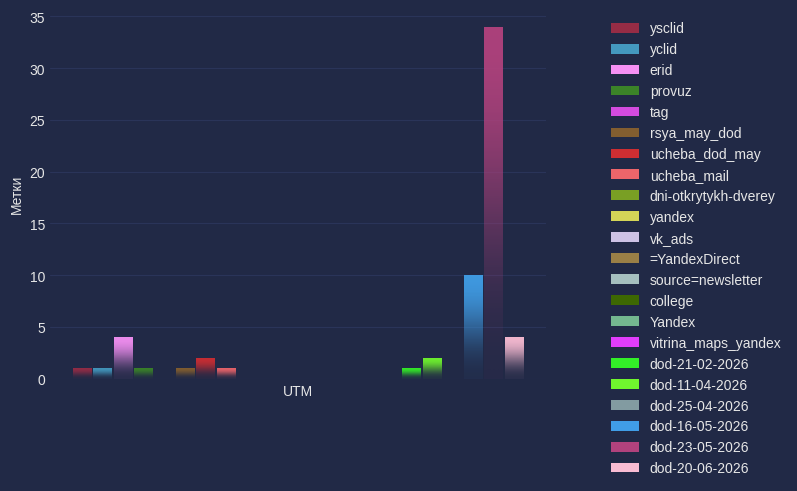

[1, 1, 4, 1, 0, 1, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 0, 10, 34, 4]


(52, 2)

In [99]:
# @title UTM на 23 мая (онлайн)

spisok_utm1 = ['ysclid', 'yclid', 'erid','provuz', 'tag', 'rsya_may_dod', 'ucheba_dod_may', 'ucheba_mail',  'dni-otkrytykh-dverey', 'yandex', 'vk_ads','=YandexDirect', 'source=newsletter','college', 'Yandex', 'vitrina_maps_yandex', 'dod-21-02-2026', 'dod-11-04-2026', 'dod-25-04-2026', 'dod-16-05-2026', 'dod-23-05-2026', 'dod-20-06-2026']

finals_utms = total_print(dataset, '23 мая (онлайн)', spisok_utm1)

[print(spisok_utm1[i], finals_utms[i]) for i in range(len(spisok_utm1))]

sylka1 = data_dod(dataset, '23 мая (онлайн)')

grafic(spisok_utm1, finals_utms)

print(finals_utms)

sylka1.shape

ysclid 7
yclid 58
dodreg 2
prk_yandex_june 25
rsya_yandex_may 22
kolledzh_yandex_may 16
vk_ads 1
ucheba_june_banner 1
erid 4
tag 1
dni-otkrytykh-dverey 1
yandex 65
vk_ads 1
=YandexDirect 0
priemnaya_komissiya_rosnou 1
college 0
Yandex 0
vitrina_maps_yandex 0
dod-25-04-2026 2
dod-20-06-2026 255


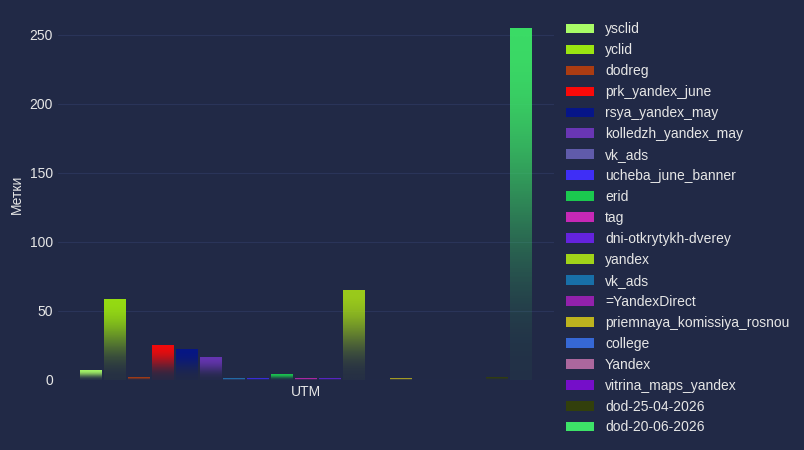

[7, 58, 2, 25, 22, 16, 1, 1, 4, 1, 1, 65, 1, 0, 1, 0, 0, 0, 2, 255]


(269, 2)

In [100]:
# @title UTM на 20 июня 2026

spisok_utm1 = ['ysclid', 'yclid', 'dodreg', 'prk_yandex_june', 'rsya_yandex_may', 'kolledzh_yandex_may', 'vk_ads', 'ucheba_june_banner', 'erid', 'tag', 'dni-otkrytykh-dverey', 'yandex', 'vk_ads', '=YandexDirect',  'priemnaya_komissiya_rosnou','college', 'Yandex', 'vitrina_maps_yandex','dod-25-04-2026', 'dod-20-06-2026']

finals_utms = total_print(dataset, '20 июня 2026', spisok_utm1)

[print(spisok_utm1[i], finals_utms[i]) for i in range(len(spisok_utm1))]

sylka1 = data_dod(dataset, '20 июня 2026')

grafic(spisok_utm1, finals_utms)

print(finals_utms)

sylka1.shape

ysclid 5
yclid 63
dodreg 2
prk_yandex_june 2
rsya_yandex_may 4
tamozhnya_july 4
kolledzh_july_dod 1
vk_ads 1
maps_july_yandex 2
erid 0
tag 0
dni-otkrytykh-dverey 0
yandex 24
vk_ads 1
=YandexDirect 0
priemnaya_komissiya_rosnou 0
college 0
Yandex 0
vitrina_maps_yandex 0
dod-20-06-2026 16
dod-04-07-2026 206


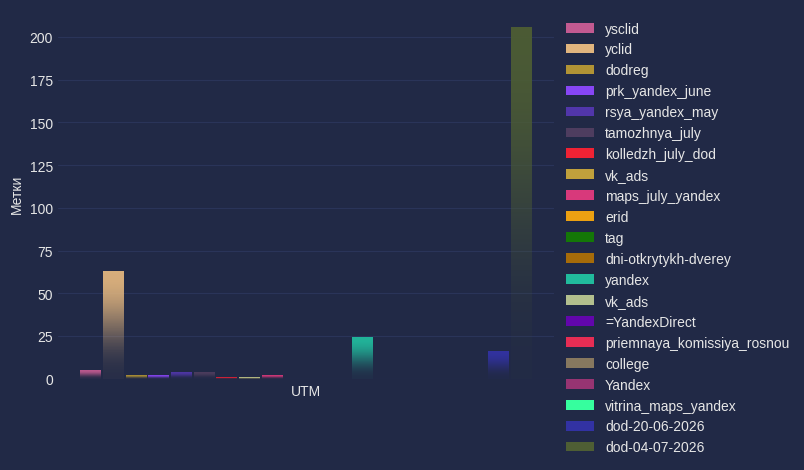

[5, 63, 2, 2, 4, 4, 1, 1, 2, 0, 0, 0, 24, 1, 0, 0, 0, 0, 0, 16, 206]


(225, 2)

In [101]:
# @title UTM на 4 июля 2026

spisok_utm1 = ['ysclid', 'yclid', 'dodreg', 'prk_yandex_june', 'rsya_yandex_may', 'tamozhnya_july', 'kolledzh_july_dod', 'vk_ads', 'maps_july_yandex', 'erid', 'tag', 'dni-otkrytykh-dverey', 'yandex', 'vk_ads', '=YandexDirect',  'priemnaya_komissiya_rosnou','college', 'Yandex', 'vitrina_maps_yandex', 'dod-20-06-2026', 'dod-04-07-2026']

finals_utms = total_print(dataset, '4 июля 2026', spisok_utm1)

[print(spisok_utm1[i], finals_utms[i]) for i in range(len(spisok_utm1))]

sylka1 = data_dod(dataset, '4 июля 2026')

grafic(spisok_utm1, finals_utms)

print(finals_utms)

sylka1.shape

ysclid 5
yclid 40
dodreg 0
rsy_15_july_dod 25
dod_july_yandex 5
target_ed_15_july 3
kolledzh_15_july 2
dod_15_july 28
tamozhnya_july 3
ucheba_mail__june 1
vk_ads 0
maps_july_yandex 0
erid 1
tag 0
dni-otkrytykh-dverey 0
yandex 9
vk_ads 0
=YandexDirect 0
priemnaya_komissiya_rosnou 0
college 0
Yandex 0
vitrina_maps_yandex 0
dod-20-06-2026 5
dod-04-07-2026 13
dod-15-07-2026 256


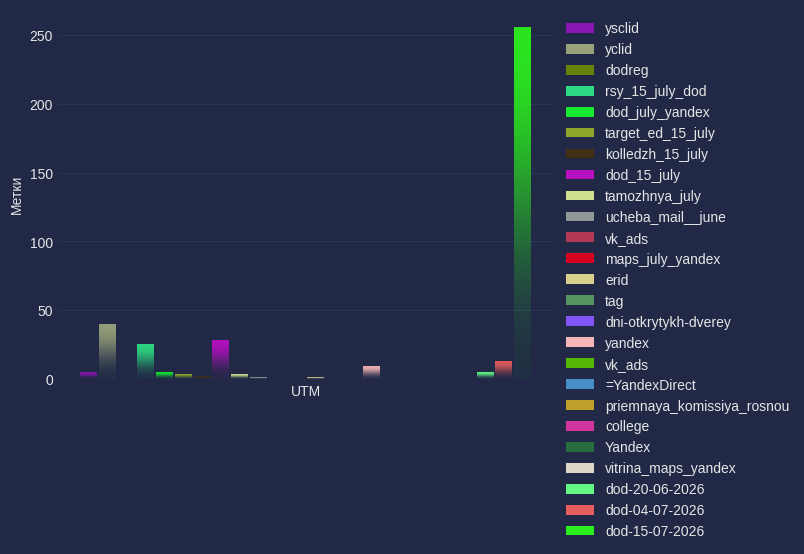

[5, 40, 0, 25, 5, 3, 2, 28, 3, 1, 0, 0, 1, 0, 0, 9, 0, 0, 0, 0, 0, 0, 5, 13, 256]


(274, 2)

In [102]:
# @title UTM на 15 июля 2026

spisok_utm1 = ['ysclid', 'yclid', 'dodreg', 'rsy_15_july_dod', 'dod_july_yandex', 'target_ed_15_july','kolledzh_15_july', 'dod_15_july', 'tamozhnya_july', 'ucheba_mail__june', 'vk_ads', 'maps_july_yandex', 'erid', 'tag', 'dni-otkrytykh-dverey', 'yandex', 'vk_ads', '=YandexDirect',  'priemnaya_komissiya_rosnou','college', 'Yandex', 'vitrina_maps_yandex', 'dod-20-06-2026', 'dod-04-07-2026', 'dod-15-07-2026']

finals_utms = total_print(dataset, '15 июля 2026', spisok_utm1)

[print(spisok_utm1[i], finals_utms[i]) for i in range(len(spisok_utm1))]

sylka1 = data_dod(dataset, '15 июля 2026')

grafic(spisok_utm1, finals_utms)

print(finals_utms)

sylka1.shape

In [103]:
# @title разделение даты
new_dataframe = pd.read_excel('form_dodreg_split_events.xlsx')

new_dataframe['Дата мероприятия'] = new_dataframe['Дата мероприятия'].str.replace('(онлайн)', '')
new_dataframe['Дата мероприятия'] = new_dataframe['Дата мероприятия'].str.replace('года', '')
for i, m in enumerate((
    "января",
    "февраля",
    "марта",
    "апреля",
    "мая",
    "июня",
    "июля",
    "августа",
    "сентября",
    "октября",
    "ноября",
    "декабря")):
  new_dataframe['Дата мероприятия'] = new_dataframe['Дата мероприятия'].str.replace(m, str(i + 1))
new_dataframe['Дата мероприятия'] = new_dataframe['Дата мероприятия'].str.strip()
new_dataframe = new_dataframe[new_dataframe['Дата мероприятия'].str.count(' ') == 2]
new_dataframe['Дата мероприятия'] = pd.to_datetime(new_dataframe['Дата мероприятия'], dayfirst=True).dt.strftime('%Y-%m-%d')

new_dataframe.to_excel('int_dates.xlsx')



In [106]:
#@title UTM-метки по месяцам мероприятий → Excel
import re
import pandas as pd
from openpyxl.styles import Font, PatternFill, Alignment

# Вставлять эту ячейку после ячеек, в которых формируются dataset/spisok_utm/spisok_utm1.
# В spisok_utm1 значения перезаписываются между мероприятиями,
# поэтому ниже сохранён общий список меток из всех ячеек 2026 года.

UTM_KNOWN_HISTORY = [
    # Базовый список spisok_utm (2024–2025)
    'ysclid', 'yclid', 'postupi_online', 'erid', 'tag',
    'dni-otkrytykh-dverey', 'yandex', 'vk_ads', 'vuzopedia', 'ucheba',
    '=YandexDirect', 'tg', 'shag_ad', 'source=newsletter', 'college',
    'Yandex', 'Yandex_dod_22', 'shag_nov',

    # Объединение всех вариантов spisok_utm1 из ячеек 2026 года
    'dod-07-02-2026', 'YandexDirect', 'tg_shag_feb', 'moy_obraz_feb_dod',
    'priemnaya_komissiya_rosnou', 'yandex_pg_feb', 'dod-21-02-2026',
    'dod-14-03-2026', 'yandex_pg', 'dod-11-04-2026', 'vkontakte',
    'banner_ucheba_11_april', 'ucheba_mail_dod_11aprl',
    'yandex_rsya_11_april', 'ege_pg_april', 'pg_april', 'dod-28-03-2026',
    'dod-25-04-2026', 'dod-16-05-2026', 'ege_may', 'rsya_may_dod',
    'prk_bakalavr_may', 'ucheba_mail', 'kolledzh_may', 'ucheba_dod_may',
    'postupi_anons_may', 'vitrina_maps_yandex', 'provuz', 'dod-23-05-2026',
    'dod-20-06-2026', 'dodreg', 'prk_yandex_june', 'rsya_yandex_may',
    'kolledzh_yandex_may', 'ucheba_june_banner', 'tamozhnya_july',
    'kolledzh_july_dod', 'maps_july_yandex', 'dod-04-07-2026',
    'rsy_15_july_dod', 'dod_july_yandex', 'target_ed_15_july',
    'kolledzh_15_july', 'dod_15_july', 'ucheba_mail__june',
    'dod-15-07-2026'
]

MONTHS_RU = {
    'января': 1, 'февраля': 2, 'марта': 3, 'апреля': 4,
    'мая': 5, 'июня': 6, 'июля': 7, 'августа': 8,
    'сентября': 9, 'октября': 10, 'ноября': 11, 'декабря': 12
}

MONTH_NAMES = {
    1: 'Январь', 2: 'Февраль', 3: 'Март', 4: 'Апрель',
    5: 'Май', 6: 'Июнь', 7: 'Июль', 8: 'Август',
    9: 'Сентябрь', 10: 'Октябрь', 11: 'Ноябрь', 12: 'Декабрь'
}

MONTH_PATTERN = '|'.join(MONTHS_RU.keys())

DATE_RE = re.compile(
    rf'(?i)\b(\d{{1,2}})\s+({MONTH_PATTERN})(?:\s+(20\d{{2}}))?\b'
)

# Делим только между датами. Запятую в тексте "(онлайн, колледж)"
# не считаем разделителем мероприятий.
EVENT_SEPARATOR_RE = re.compile(
    rf',\s*(?=\d{{1,2}}\s+(?:{MONTH_PATTERN})\b)', re.IGNORECASE
)

# В исходной таблице у этих мероприятий год не указан.
# 12 октября и 16 ноября относятся к 2024 году; остальные даты — к 2026.
EVENT_YEAR_OVERRIDES = {
    (12, 10): 2024,
    (16, 11): 2024,
    (21, 2): 2026,
    (28, 3): 2026,
    (25, 4): 2026,
    (23, 5): 2026,
}


def split_event_value(value):
    """Возвращает список дат и поддерживает текст и уже разбитые списки."""
    if value is None:
        return []

    if isinstance(value, (list, tuple, set)):
        result = []
        for item in value:
            result.extend(split_event_value(item))
        return result

    try:
        if pd.isna(value):
            return []
    except (TypeError, ValueError):
        pass

    text = str(value).strip()
    if not text:
        return []

    return [
        part.strip()
        for part in EVENT_SEPARATOR_RE.split(text)
        if part.strip()
    ]


def parse_event_date(value):
    """Возвращает (год, месяц, день); неизвестный год не подставляется молча."""
    text = str(value).strip().lower()
    match = DATE_RE.search(text)

    if not match:
        return None

    day = int(match.group(1))
    month = MONTHS_RU[match.group(2).lower()]
    year_text = match.group(3)

    if year_text:
        year = int(year_text)
    else:
        year = EVENT_YEAR_OVERRIDES.get((day, month))

        if year is None:
            raise ValueError(
                f'В дате "{value}" не указан год и для неё нет правила. '
                f'Добавьте запись ({day}, {month}): год в EVENT_YEAR_OVERRIDES.'
            )

    return year, month, day


# 1. Проверяем, что исходная таблица загружена.
if 'dataset' not in globals() or not isinstance(dataset, pd.DataFrame):
    raise NameError(
        'Не найдена таблица dataset. Сначала выполните ячейки ноутбука, '
        'которые загружают исходный Excel.'
    )

required_columns = ['Дата мероприятия', 'URL отправки']
missing_columns = [col for col in required_columns if col not in dataset.columns]

if missing_columns:
    raise KeyError(f'В dataset отсутствуют столбцы: {missing_columns}')


# 2. Собираем метки из переменных ноутбука и исторического списка.
utm_candidates = []

for variable_name in ('spisok_utm', 'spisok_utm1'):
    variable_value = globals().get(variable_name, [])

    if isinstance(variable_value, (list, tuple, set)):
        for item in variable_value:
            if item is not None and str(item).strip():
                utm_candidates.append(str(item).strip())

utm_candidates.extend(UTM_KNOWN_HISTORY)

# "=YandexDirect" и "YandexDirect" — один и тот же поисковый маркер.
# Убираем начальный знак "=" и дубли, сохраняя порядок.
all_utms = list(dict.fromkeys(
    marker.lstrip('=')
    for marker in utm_candidates
    if marker.lstrip('=')
))

if not all_utms:
    raise ValueError('Не найдено ни одной UTM-метки.')

print(f'Уникальных UTM-меток в обработке: {len(all_utms)}')


# 3. Разворачиваем записи по датам мероприятий.
# Если человек зарегистрировался на несколько мероприятий, его запись
# войдёт в подсчёт каждого выбранного мероприятия.
event_rows = []
unparsed_event_labels = set()

for source_row_index, row in dataset.iterrows():
    event_items = split_event_value(row['Дата мероприятия'])

    url_value = row['URL отправки']

    try:
        url_is_empty = pd.isna(url_value)
    except (TypeError, ValueError):
        url_is_empty = False

    url = '' if url_is_empty else str(url_value).strip()

    for event_label in event_items:
        parsed = parse_event_date(event_label)

        if parsed is None:
            unparsed_event_labels.add(event_label)
            continue

        year, month, day = parsed

        event_rows.append({
            'Год': year,
            'Месяц': month,
            'День': day,
            'Дата мероприятия': event_label,
            'URL отправки': url,
            '_source_row': source_row_index,
        })

if not event_rows:
    raise ValueError(
        'Не удалось распознать даты мероприятий в столбце «Дата мероприятия».'
    )

df_events = pd.DataFrame(event_rows)


# 4. Сводная таблица: год × месяц.
monthly_rows = []

for (year, month), group in df_events.groupby(['Год', 'Месяц'], sort=True):
    urls = group['URL отправки']
    usable_urls = [url for url in urls if url]

    result_row = {
        'Год': int(year),
        'Месяц': int(month),
        'Название месяца': MONTH_NAMES[int(month)],
        'Мероприятий': int(group['Дата мероприятия'].nunique()),
        'Всего записей по мероприятиям': int(len(group)),
        'Всего URL': int(len(usable_urls)),
    }

    # Считаем каждую метку максимум один раз на URL.
    # Поиск — по вхождению текста метки в URL, как в прежнем коде.
    for marker in all_utms:
        result_row[marker] = sum(marker in url for url in usable_urls)

    monthly_rows.append(result_row)

monthly_df = pd.DataFrame(monthly_rows).sort_values(
    ['Год', 'Месяц']
).reset_index(drop=True)


# 5. Подробная таблица: отдельная строка на дату каждого мероприятия.
detail_rows = []

for (year, month, day, event_label), group in df_events.groupby(
    ['Год', 'Месяц', 'День', 'Дата мероприятия'], sort=True
):
    urls = group['URL отправки']
    usable_urls = [url for url in urls if url]

    result_row = {
        'Год': int(year),
        'Месяц': int(month),
        'Название месяца': MONTH_NAMES[int(month)],
        'Дата мероприятия': event_label,
        'Всего записей по мероприятию': int(len(group)),
        'Всего URL': int(len(usable_urls)),
    }

    for marker in all_utms:
        result_row[marker] = sum(marker in url for url in usable_urls)

    detail_rows.append(result_row)

detail_df = pd.DataFrame(detail_rows).reset_index(drop=True)


# 6. Контрольный лист — все метки и количество исходных URL,
# в которых каждая метка встречается.
source_urls = [
    str(value).strip()
    for value in dataset['URL отправки'].dropna()
    if str(value).strip()
]

audit_df = pd.DataFrame({
    'UTM-метка': all_utms,
    'Найдено в исходных URL': [
        sum(marker in url for url in source_urls)
        for marker in all_utms
    ],
}).sort_values(
    ['Найдено в исходных URL', 'UTM-метка'],
    ascending=[False, True]
).reset_index(drop=True)


# 7. Записываем Excel с фильтрами, закреплённой строкой заголовков
# и форматированием.
OUT_FILE = 'utm_by_month.xlsx'

with pd.ExcelWriter(OUT_FILE, engine='openpyxl') as writer:
    monthly_df.to_excel(writer, sheet_name='UTM по месяцам', index=False)
    detail_df.to_excel(writer, sheet_name='Детально по датам', index=False)
    audit_df.to_excel(writer, sheet_name='Список UTM', index=False)

    workbook = writer.book

    for worksheet in workbook.worksheets:
        worksheet.freeze_panes = 'A2'
        worksheet.auto_filter.ref = worksheet.dimensions
        worksheet.sheet_view.showGridLines = False
        worksheet.row_dimensions[1].height = 34

        for cell in worksheet[1]:
            cell.font = Font(bold=True, color='FFFFFF')
            cell.fill = PatternFill(fill_type='solid', fgColor='17365D')
            cell.alignment = Alignment(
                horizontal='center',
                vertical='center',
                wrap_text=True
            )

        # Ширина каждого столбца подстраивается под содержимое,
        # но ограничена сверху, чтобы таблицу было удобно просматривать.
        for column_cells in worksheet.columns:
            column_letter = column_cells[0].column_letter
            longest = max(
                (
                    len(str(cell.value))
                    for cell in column_cells
                    if cell.value is not None
                ),
                default=10
            )

            worksheet.column_dimensions[column_letter].width = min(
                max(longest + 2, 12), 34
            )


print(f'Файл сохранён: {OUT_FILE}')
print(f'Строк в сводке по месяцам: {len(monthly_df)}')
print(f'Строк с детализацией по датам: {len(detail_df)}')

if unparsed_event_labels:
    print(
        'ВНИМАНИЕ: не распознаны следующие фрагменты дат; '
        'проверьте их вручную:',
        sorted(unparsed_event_labels)
    )
else:
    print('Все фрагменты дат мероприятий распознаны.')

# Автоматически скачиваем файл в Google Colab.
try:
    from google.colab import files
    files.download(OUT_FILE)
except ImportError:
    print('Автоматическое скачивание доступно только в Google Colab.')


Уникальных UTM-меток в обработке: 63
Файл сохранён: utm_by_month.xlsx
Строк в сводке по месяцам: 23
Строк с детализацией по датам: 41
Все фрагменты дат мероприятий распознаны.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>